In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from keras.models import Sequential
from keras.layers import Dense, Dropout, LSTM
from sklearn.preprocessing import MinMaxScaler
from keras.callbacks import EarlyStopping

In [3]:
data_train = pd.read_csv("/home/arkade01/projetos/IA_Aulas/C.RNA/datasets/Google_Stock_Price_Train.csv")
data_test = pd.read_csv("/home/arkade01/projetos/IA_Aulas/C.RNA/datasets/Google_Stock_Price_Test.csv")

In [4]:
data_train

,Date,Open,High,Low,Close,Volume
0,1/3/2012,325.25,332.83,324.97,663.59,"7,380,500"
1,1/4/2012,331.27,333.87,329.08,666.45,"5,749,400"
2,1/5/2012,329.83,330.75,326.89,657.21,"6,590,300"
3,1/6/2012,328.34,328.77,323.68,648.24,"5,405,900"
4,1/9/2012,322.04,322.29,309.46,620.76,"11,688,800"
...,...,...,...,...,...,...
1253,12/23/2016,790.90,792.74,787.28,789.91,"623,400"
1254,12/27/2016,790.68,797.86,787.66,791.55,"789,100"
1255,12/28/2016,793.70,794.23,783.20,785.05,"1,153,800"
1256,12/29/2016,783.33,785.93,778.92,782.79,"744,300"


In [5]:
data_train.shape

(1258, 6)

In [15]:
train_set = data_train.iloc[:, 1:2]
train_set

,Open
0,325.25
1,331.27
2,329.83
3,328.34
4,322.04
...,...
1253,790.90
1254,790.68
1255,793.70
1256,783.33


In [18]:
mms = MinMaxScaler()

train_set_mms= mms.fit_transform(train_set) # deixando os dados de open entre 0 e 1
train_set_mms

array([[0.08581368],
       [0.09701243],
       [0.09433366],
       ...,
       [0.95725128],
       [0.93796041],
       [0.93688146]], shape=(1258, 1))

> O ojetivo é, com base em dados historicos, levando em consideração 60 dias antes de cada dia, prever o comportamento do google stock markets nos dias seguintes aos dados historicos usados no treinamento


In [19]:
X_train = []
y_train = []

for i in range(60, train_set_mms.shape[0]): #começa em 60 pois apenas a partir do 61° valor se tem 60 dias anteriores
    X_train.append(train_set_mms[i-60:i,0]) # i-60:i, lê-se: pegando da posição atual, contamos menos 60 dias e colocamos esse intervalo no vetor X_train
    y_train.append(train_set_mms[i,0])
X_train, y_train = np.array(X_train), np.array(y_train)

In [ ]:
X_train # aqui podemos ver que o dataset diminuiu em 60 linhas pelo motivo citado acima

array([[0.08581368, 0.09701243, 0.09433366, ..., 0.07846566, 0.08034452,
        0.08497656],
       [0.09701243, 0.09433366, 0.09156187, ..., 0.08034452, 0.08497656,
        0.08627874],
       [0.09433366, 0.09156187, 0.07984225, ..., 0.08497656, 0.08627874,
        0.08471612],
       ...,
       [0.92106928, 0.92438053, 0.93048218, ..., 0.95475854, 0.95204256,
        0.95163331],
       [0.92438053, 0.93048218, 0.9299055 , ..., 0.95204256, 0.95163331,
        0.95725128],
       [0.93048218, 0.9299055 , 0.93113327, ..., 0.95163331, 0.95725128,
        0.93796041]], shape=(1198, 60))

In [21]:
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1)) # reshape para o formato exigido pela camada LSTM: (amostras, timesteps, features)
X_train.shape

(1198, 60, 1)

In [ ]:
modelo = Sequential([
    LSTM(units=50, return_sequences=True),
    Dropout(0.2),
    LSTM(units=50, return_sequences=True),
    Dropout(0.2),
    LSTM(units=50, return_sequences=True),
    Dropout(0.2),
    LSTM(units=50),
    Dropout(0.2),
    Dense(1)     
])

E0000 00:00:1780933096.615651   16310 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1780933096.615896   22848 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
E0000 00:00:1780933096.642624   16310 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1780933096.642639   22848 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1780933096.659960   16310 gpu_device.cc:2365] Cannot dlopen some GPU l

In [31]:
modelo.compile(optimizer="adam", loss="mean_squared_error")

es = EarlyStopping(monitor="loss", mode = "min", verbose=1, patience=30)

history = modelo.fit(X_train,y_train,epochs=500,batch_size=32,callbacks=es)

Epoch 1/500


38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - loss: 0.0013
Epoch 2/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0013
Epoch 3/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.0012
Epoch 4/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0011
Epoch 5/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0011
Epoch 6/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0013
Epoch 7/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0014
Epoch 8/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0011
Epoch 9/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0012
Epoch 10/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0011
Epoch 11/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0012
Epoch 12/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0012
Epoch 13/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0011
Epoch 14/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0011
Epoch 15/500
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0011
E

In [32]:
real_stock_price = data_test.iloc[:, 1:2].values
real_stock_price

array([[778.81],
       [788.36],
       [786.08],
       [795.26],
       [806.4 ],
       [807.86],
       [805.  ],
       [807.14],
       [807.48],
       [807.08],
       [805.81],
       [805.12],
       [806.91],
       [807.25],
       [822.3 ],
       [829.62],
       [837.81],
       [834.71],
       [814.66],
       [796.86]])

In [33]:
data_total = pd.concat((data_train["Open"], data_test["Open"]), axis=0)
data_total

0     325.25
1     331.27
2     329.83
3     328.34
4     322.04
       ...  
15    829.62
16    837.81
17    834.71
18    814.66
19    796.86
Name: Open, Length: 1278, dtype: float64

In [34]:
inputs = data_total[len(data_total)-len(data_test)-60:].values # aqui pegamos os últimos 60 dias do dataset total para usar como input para a previsão dos próximos 20 dias
inputs = inputs.reshape(-1, 1)
inputs

array([[779.  ],
       [779.66],
       [777.71],
       [786.66],
       [783.76],
       [781.22],
       [781.65],
       [779.8 ],
       [787.85],
       [798.24],
       [803.3 ],
       [795.  ],
       [804.9 ],
       [816.68],
       [806.34],
       [801.  ],
       [808.35],
       [795.47],
       [782.89],
       [778.2 ],
       [767.25],
       [750.66],
       [774.5 ],
       [783.4 ],
       [779.94],
       [791.17],
       [756.54],
       [755.6 ],
       [746.97],
       [755.2 ],
       [766.92],
       [771.37],
       [762.61],
       [772.63],
       [767.73],
       [764.26],
       [760.  ],
       [771.53],
       [770.07],
       [757.44],
       [744.59],
       [757.71],
       [764.73],
       [761.  ],
       [772.48],
       [780.  ],
       [785.04],
       [793.9 ],
       [797.4 ],
       [797.34],
       [800.4 ],
       [790.22],
       [796.76],
       [795.84],
       [792.36],
       [790.9 ],
       [790.68],
       [793.7 ],
       [783.33

In [35]:
inputs = mms.transform(inputs)
X_test =[]
for i in range(60,80):
    X_test.append(inputs[i-60:i,0])
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1],1))
predicted_stock_price = modelo.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step


/home/arkade01/projetos/IA_Aulas/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [36]:
predicted_stock_price = mms.inverse_transform(predicted_stock_price)

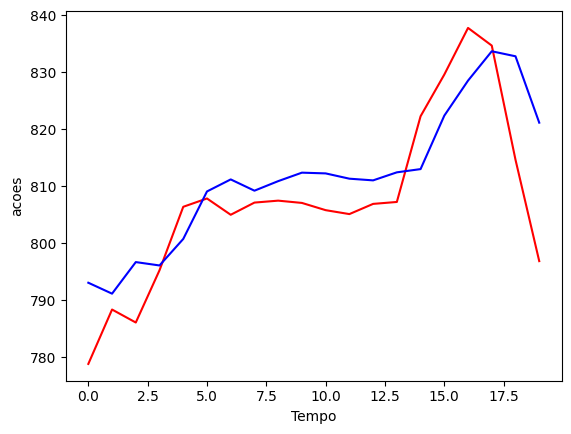

In [37]:
plt.plot(real_stock_price, color="red", label="dados reais")
plt.plot(predicted_stock_price, color="blue", label="dados previstos")
plt.xlabel("Tempo")
plt.ylabel("acoes")
plt.show()